# Imports

In [1]:
import sys
import pandas as pd
import os
import numpy as np
import plotly.io as pio
import plotly.express as px
import math
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import seaborn as sns
sys.path.append('../..')
from plotly.graph_objs import Figure
from functools import reduce
from definitions import ROOT_DIR, KGS_DIR

# Utils

In [2]:
FIGURES_DIR = os.path.join(ROOT_DIR, 'assets', 'corpus_statistics')
os.makedirs(FIGURES_DIR, exist_ok=True)

In [3]:
pio.templates.default = "seaborn"

In [4]:
def save_fig(fig : Figure, filename : str) -> None:
    fig.write_image(os.path.join(FIGURES_DIR, filename))

def show(fig : Figure) -> None:
    fig.update_layout(font_size = 12)
    fig.show()

# Corpus

- Load the data

In [22]:
def load_data(
    name : str,
    classification : str
) -> pd.DataFrame:
    
    data_path = os.path.join(KGS_DIR, name, classification, 'data.jsonl')
    data = pd.read_json(data_path, lines=True)
    pseudo_labels = data['pseudo_labels'].apply(lambda x : x['llm:deepseek-chat'])
    data['labled'] = pseudo_labels.apply(lambda x : max([item['score'] for item in x])) / 10
    data['Year'] = data['date'].apply(lambda x : int(str(x)[:4]))

    return data

In [21]:
data['labled']

0        8.0
1        8.0
2       10.0
3        0.0
4        8.0
        ... 
5800     8.0
5801     9.0
5802     9.0
5803     8.0
5804     8.0
Name: labled, Length: 5805, dtype: float64

In [26]:
config = 'industry_of_future_v2'
classification = 'corpus_annotation_deepseek'
data = load_data(config, classification)

In [27]:
data = data[(data['Year'] >= 2022) & (data['Year'] <= 2026)]

In [28]:
data.head()

,id,title,abstract,keywords,authors,venues,teams,date,pseudo_labels,labled,Year
0,5420658,Machine Learning Based Environmental Impact Pr...,The construction sector significantly contribu...,"[environment product declaration, life cycle a...","[Bishwash Neupane, Benoit Hilloulin, Raphael C...","[spi.gciv.ec, info.info-ia, info.info-lg, sde.ie]","[GEM, LS2N]",2026-11-21 00:00:00+00:00,{'qwen:Qwen--Qwen3-Embedding-0.6B': [{'label':...,0.8,2026
1,5562561,TWO-DIMENSIONAL INFRARED EMISSIVITY OF A SEA S...,The sea surface intrinsic infrared emission is...,"[modeling, sea surface, infrared emissivity]","[Léa Ould-Ahmed, Christophe Bourlier, Nicolas ...","[spi.tron, spi, spi.other]",[IETR],2026-08-09 00:00:00+00:00,{'qwen:Qwen--Qwen3-Embedding-0.6B': [{'label':...,0.8,2026
2,5556678,Vision and Attention-Based Models for Process ...,Abstract. Anomaly detection is a fundamental s...,"[computer vision, process control, attention m...","[Yunfan Li, Elodie Paquet, Sébastien Levilly, ...","[info.info-cv, info.info-ai, info.info-ti, spi...",[LS2N],2026-07-08 00:00:00+00:00,{'qwen:Qwen--Qwen3-Embedding-0.6B': [{'label':...,1.0,2026
3,5554251,Exponential stabilization of two coupled linea...,This work addresses the stabilization problem ...,"[korteweg de vries system, backstepping, expon...","[Youssef Khalifeh, Ihab Haidar, Jean-Pierre Ba...","[spi, math]",[LS2N],2026-07-07 00:00:00+00:00,{'qwen:Qwen--Qwen3-Embedding-0.6B': [{'label':...,0.0,2026
4,5559591,Load-dependent travel time estimation for carg...,This work addresses an extension of the pickup...,[city logistics vehicle routing metaheuristics],"[Fabien Lehuédé, Awen Jacq-Baudet, Leandro Mon...",[info.info-ro],[LS2N],2026-07-06 00:00:00+00:00,{'qwen:Qwen--Qwen3-Embedding-0.6B': [{'label':...,0.8,2026


In [30]:
STEP = 0.01

THRESHOLDS = np.arange(
    data['labled'].min() + STEP,
    data['labled'].max() - STEP,
    STEP
)

- By Year

In [17]:
fig = px.bar(
    data_frame=data['Year']
        .value_counts()
        .reset_index()
        .rename(columns={ "Year" : "Year", "count" : "Number Of Articles" }),
    x="Year",
    y="Number Of Articles",
    text = "Number Of Articles",
    width=800,
    height=550
)

show(fig)

In [18]:
fig = px.pie(
    data_frame=data['Year']
        .value_counts()
        .reset_index()
        .rename(columns={ "Year" : "Year", "count" : "Number Of Articles" }),
    names="Year",
    values="Number Of Articles",
    width=800,
    height=550
)

show(fig)

In [31]:
# Total number of articles per year
year_totals = data['Year'].value_counts()

records = []

for t in THRESHOLDS:

    years = (
        data[data["labled"] > t]["Year"]
            .value_counts()
            .sort_index()
    )

    for year in year_totals.index:

        count = years.get(year, 0)
        percentage = 100 * count / year_totals[year]

        records.append({
            "Threshold": t,
            "Year": str(year),
            "Percentage": percentage
        })

df = pd.DataFrame(records)

fig = px.line(
    df,
    x="Threshold",
    y="Percentage",
    color="Year",
    markers=True,
    width=800,
    height=550,
    labels={
        "Percentage": "Articles (%)",
        "Threshold": "Confidence Threshold"
    }
)

fig.update_yaxes(ticksuffix="%")
show(fig)

In [32]:
N = len(data)

df = pd.DataFrame({
    "Threshold": THRESHOLDS,
    "Percentage": [
        100 * (data["labled"] > t).sum() / N
        for t in THRESHOLDS
    ]
})

fig = px.line(
    df,
    x="Threshold",
    y="Percentage",
    markers=True,
    width=800,
    height=550,
    labels={
        "Threshold": "Confidence Threshold",
        "Percentage": "Articles (%)"
    }
)

fig.update_yaxes(ticksuffix="%")
show(fig)

In [33]:
graph_data = (
    data[['Year', 'labled']]
        .groupby(by='Year')
        .mean()
        .reset_index()
)

graph_data['text'] = graph_data['labled'].apply(lambda x : f"{x:.3f}")

fig = px.bar(
    graph_data,
    x="Year",
    y="labled",
    width=800,
    height=550,
    labels={
        "Year": "Year",
        "labled": "Avg. Relevance"
    },
    text = "text",
)

show(fig)

- Keywords

In [34]:
keywords = reduce(lambda a,b : a + b, data['keywords'])
keywords = list(map(str.lower, keywords))
index, count = np.unique(keywords,return_counts=True)
keywords = pd.Series(index=index,data=count).sort_values(ascending=False)
print(len(keywords))

13181


In [35]:
fig = px.bar(
    data_frame = keywords.iloc[:13].sort_values(ascending=True).reset_index(),
    y = "index",
    x = 0,
    text = 0,
    width=800,
    height=450
)
fig.update_layout(xaxis_title="Frequency",yaxis_title="Keyword")
save_fig(fig, 'top_10_most_frequent_keywords.pdf')
show(fig)

- Categories

In [36]:
sub_categories = reduce(lambda a,b : a + b, data['venues'])
sub_categories = pd.Series(sub_categories).value_counts()
categories = sub_categories.groupby(by=lambda x : x.split('.')[0]).sum().sort_values(ascending=False)
categories

spi     2868
info    2431
chim     943
phys     681
sdv      629
shs      540
sde      220
math     189
stat     100
scco      70
sdu       61
qfin      48
nlin      18
Name: count, dtype: int64

In [37]:
fig = px.bar(
    data_frame = categories.sort_values(ascending=True).reset_index(),
    y = "index",
    x = "count",
    text = "count",
    width=800,
    height=450
)
fig.update_layout(xaxis_title="Frequency",yaxis_title="Category")
save_fig(fig, 'top_10_most_frequent_categories.pdf')
show(fig)

- Teams

In [38]:
teams = list(set(reduce(lambda a,b : a + b, data["teams"])))
# teams.remove('LS2N')

for team in teams:
    data[team] = data["teams"].apply(lambda x : team in x)

In [39]:
fig = px.bar(
    data_frame = data[teams]
        .sum()
        .reset_index()
        .rename(columns = { "index" : "Team", 0 : "Number Of Articles" })
        .sort_values(by = "Number Of Articles"),
    y = "Team",
    x = "Number Of Articles",
    text = "Number Of Articles",
    width = 960,
    height = 600
)

save_fig(fig, 'teams_distribution.pdf')
fig.show()

In [40]:
fig = px.pie(
    data_frame = data[teams]
        .sum()
        .reset_index()
        .rename(columns = { "index" : "Team", 0 : "Number Of Articles" })
        .sort_values(by = "Number Of Articles"),
    names = "Team",
    values = "Number Of Articles",
    width = 960,
    height = 600
)

save_fig(fig, 'teams_distribution_labeld_only.pdf')
fig.show()

In [41]:
df = pd.concat([
    (100 * data[data['labled'].gt(threshold)][teams].sum() / data[teams].sum()) \
        .reset_index() \
        .rename(columns = { "index" : "Team", 0 : "Percentage" }).set_axis(
            pd.Series([threshold] * len(teams), name="Threshold"),
            axis=0
        ).reset_index()
    for threshold in THRESHOLDS
])

fig = px.line(
    df,
    x="Threshold",
    y="Percentage",
    color="Team",
    markers=True,
    width=800,
    height=550,
    labels={
        "Percentage": "Articles (%)",
        "Threshold": "Confidence Threshold"
    }
)

fig.update_yaxes(ticksuffix="%")
fig.show()

In [42]:
threshold = 0.5

fig = px.pie(
    data_frame = data[data['labled'].gt(threshold)][teams]
        .sum()
        .reset_index()
        .rename(columns = { "index" : "Team", 0 : "Number Of Articles" })
        .sort_values(by = "Number Of Articles"),
    names = "Team",
    values = "Number Of Articles",
    width = 960,
    height = 600
)

save_fig(fig, 'teams_distribution_labeld_only.pdf')
fig.show()

- DSIs

In [43]:
# classified Vs Not classified
threshold = 0.5

fig = px.pie(
    names = ['Labeled', 'Not labeled'],
    values = data['labled'].gt(threshold).value_counts(),
    width = 850,
    height = 600
)

save_fig(fig, "labeled.pdf")
show(fig)

In [45]:
# Number of Labels
threshold = 0.5
labels = data['pseudo_labels'].apply(lambda x : x['llm:deepseek-chat']).apply(lambda x : [item['label'] for item in x if item['score'] >= threshold])
labels = reduce(lambda a, b : a+b, labels.tolist())
labels = pd.Series(labels).value_counts()
labels.reset_index()

,index,count
0,Monitoring and Analysis,3721
1,Eco-responsible Processes,2472
2,Digital Engineering of Products and Processes,2447
3,Composites and New Materials,1634
4,Processes and Assembly,1599
5,Industrial Digitalization,1311
6,Eco-design,1013
7,Industrial Organization Performance,1012
8,Decarbonization of Energy,988
9,Recycling / Reuse,904


In [46]:
fig = px.pie(
    data_frame = labels
        .sort_values()
        .reset_index()
        .rename(columns={ 'index' : 'DSI', 'count' : 'Number Of Articles' }),
    names = "DSI",
    values = "Number Of Articles",
    # text = "Number Of Articles",
    width = 960,
    height = 600
)

save_fig(fig, 'dsis_distribution.pdf')
show(fig)

- Team By Domain :

In [66]:
threshold = 0.4

teams_labels = []

for idx, row in data.iterrows():

    for team in row['teams']:

        # if team == 'LS2N':
        #     continue

        for label in row['pseudo_labels']['qwen:Qwen--Qwen3-Embedding-0.6B']:

            if label['score'] < threshold:
                continue

            teams_labels.append({ "team" : team, "label" : label['label'] })

teams_labels = pd.DataFrame(teams_labels)
teams_labels = teams_labels[['team', 'label']].value_counts().reset_index()

In [50]:
from src.envirenment import env

In [58]:
teams_labels.head()

,team,label,count
0,LS2N,Robotics,192
1,LS2N,Augmentation of Human Capabilities in Manufact...,121
2,LS2N,Industrial Digitalization,84
3,GEM,Composites and New Materials,70
4,LS2N,Monitoring and Analysis,68


In [64]:
mapping = { 
    d.sub_domain : (d.domain if d.domain != 'Industry 5.0' else 'Human-Centric Enterprise')
    for d in env.fields['industry_of_future'].domains 
}

In [65]:
set(mapping.values())

{'Advanced Production Technologies',
 'Human-Centric Enterprise',
 'Industrial Digitalization',
 'Sustainable Industry'}

In [67]:
teams_labels['label'] = teams_labels['label'].apply(mapping.get)
teams_labels = teams_labels.groupby(by=['team', 'label']).sum().reset_index()
teams_labels

fig = px.bar(
    data_frame = teams_labels,
    x = "count",
    y = "team",
    color = "label",
    width = 1200,
    height = 600,
)

fig.update_layout(barmode='stack', yaxis={'categoryorder':'total ascending'})
fig.update_layout(xaxis_title = "Number of Articles", yaxis_title = "Team")

save_fig(fig, 'teams_by_sub_domain.pdf')
show(fig)

In [71]:
# 1. Setup grid dimensions
teams = teams_labels['team'].unique()
n_teams = len(teams)
cols = 1  # Set how many columns you want
rows = math.ceil(n_teams / cols)

# 2. Initialize the subplot figure
# 'specs' must be set to 'type': 'domain' for pie charts
fig = make_subplots(
    rows=rows, 
    cols=cols, 
    subplot_titles=teams,
    specs=[[{'type': 'domain'}] * cols] * rows
)

# 3. Add traces in a loop
for i, label in enumerate(teams):
    
    row = (i // cols) + 1
    col = (i % cols) + 1
    
    # Filter data
    df_sub = teams_labels[teams_labels['team'] == label]
    
    # Add the pie trace
    fig.add_trace(
        go.Pie(
            labels=df_sub['label'],
            values=df_sub['count'],
            name=label
        ),
        row=row, col=col
    )

# 4. Finalize layout
fig.update_layout(
    height=400 * rows,  # Adjust height based on rows
    width=850,
    title_text="Team Label Distributions",
    showlegend=True
)

fig.show()

In [72]:
fig = px.bar(
    data_frame = teams_labels,
    x = "count",
    y = "label",
    color = "team",
    width = 1200,
    height = 600
)

fig.update_layout(barmode='stack', yaxis={'categoryorder':'total ascending'})
fig.update_layout(xaxis_title = "Number of Articles", yaxis_title = "Sub-Domain")
save_fig(fig, 'sub_domains_by_team.pdf')
show(fig)

In [74]:
# 1. Setup grid dimensions
labels = teams_labels['label'].unique()
n_labels = len(labels)
cols = 2  # Set how many columns you want
rows = math.ceil(n_labels / cols)

# 2. Initialize the subplot figure
# 'specs' must be set to 'type': 'domain' for pie charts
fig = make_subplots(
    rows=rows, 
    cols=cols, 
    subplot_titles=labels,
    specs=[[{'type': 'domain'}] * cols] * rows
)

# 3. Add traces in a loop
for i, label in enumerate(labels):

    row = (i // cols) + 1
    col = (i % cols) + 1
    
    # Filter data
    df_sub = teams_labels[teams_labels['label'] == label]
    
    # Add the pie trace
    fig.add_trace(
        go.Pie(
            labels=df_sub['team'],
            values=df_sub['count'],
            name=label
        ),
        row=row, 
        col=col
    )

# 4. Finalize layout
fig.update_layout(
    height=400 * rows,  # Adjust height based on rows
    width=850,
    title_text="Team Label Distributions",
    showlegend=True
)

fig.show()

In [ ]:
cooccurence_matrix = pd.DataFrame(
    data['pseudo_labels']
        .apply(lambda x : x["qwen:Qwen--Qwen3-Embedding-0.6B"])
        .apply(lambda x : { item['label'] : item['score'] for item in x })
        .tolist()
).corr()

cooccurence_matrix = pd.DataFrame(data=cooccurence_matrix, index=labels, columns=labels)

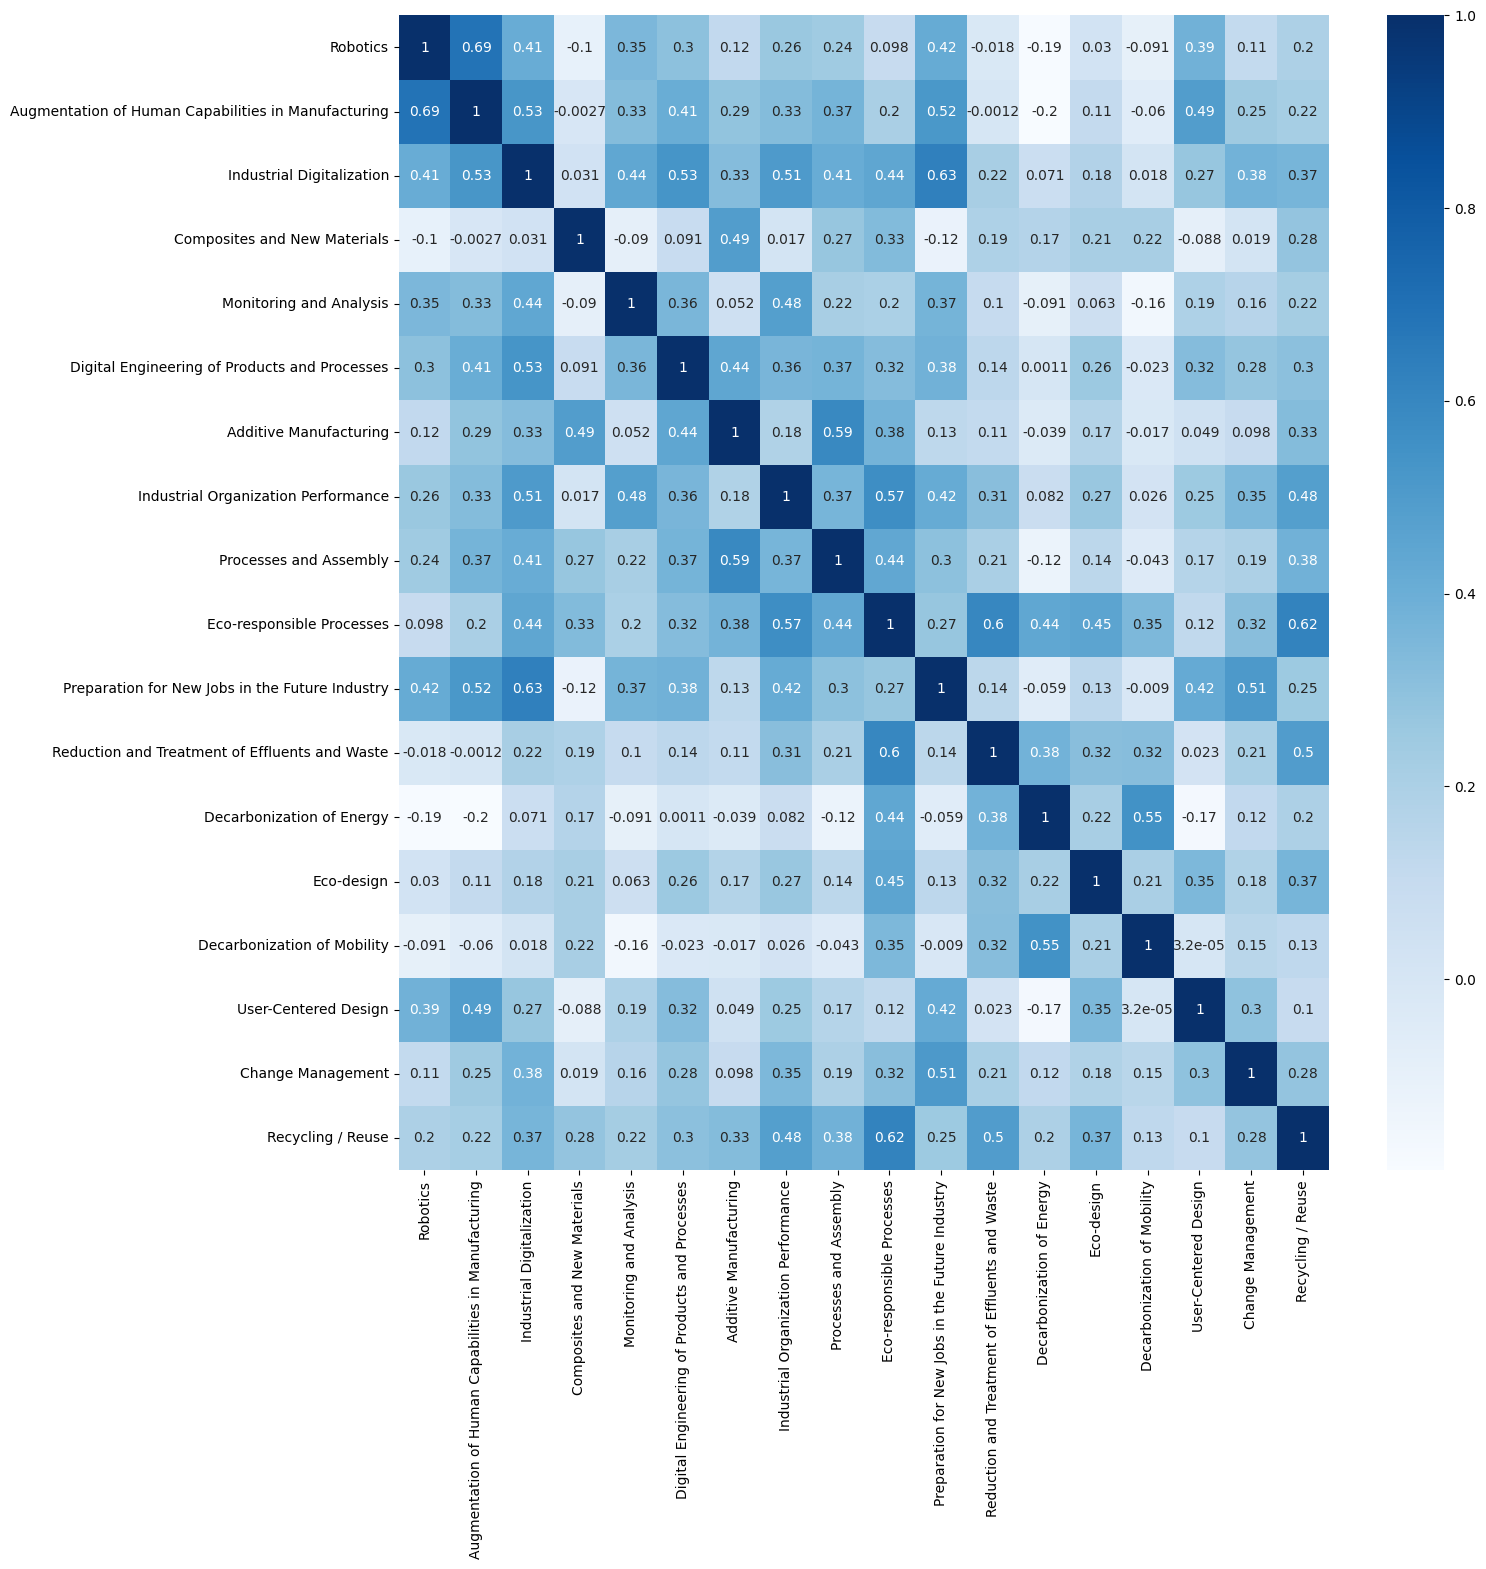

In [77]:
ax = sns.heatmap(cooccurence_matrix, cmap='Blues', annot=True)
ax.figure.set_size_inches(15, 15)